# Comparison of HYDRA-pCO₂ with SOM-FFN and SJTU-AViT

Comparison on common period 1993-2023 with: 
- **SOM-FFN v2025**, using the raw spco2_raw field
- **SJTU-AViT**, using its global monthly pCO2 field

## Imports & Setup

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from utils.paths import (
    POSTERIOR_ZARR,
    PRODUCTS_DIR,
    PRODUCT_COMPARISON_DIR,
    PRODUCT_COMPARISON_FIGURES_DIR,
    ensure_project_dirs, 
    assert_exists,
    print_paths
)

ensure_project_dirs()

POSTERIOR_PATH = POSTERIOR_ZARR
SOMFFN_PATH = PRODUCTS_DIR / "SOM-FFN_v2025_NCEI_OCADS.nc"
SJTU_AVIT_PATH = PRODUCTS_DIR / "SJTU_AVIT_1982-2023_v20250501.nc"

assert_exists(POSTERIOR_ZARR, "HYDRA-pCO2 posterior Zarr")
assert_exists(SOMFFN_PATH, "SOM-FFN product NetCDF")
assert_exists(SJTU_AVIT_PATH, "SJTU-AViT product NetCDF")

FIGURES_DIR = PRODUCT_COMPARISON_FIGURES_DIR
RESULTS_DIR = PRODUCT_COMPARISON_DIR

print_paths(
    ("Posterior", POSTERIOR_ZARR),
    ("External products", PRODUCTS_DIR)
)

#### Settings

In [ ]:
START_DATE = "1993-01-01"
END_DATE = "2023-12-01"  # constrained by SJTU-AViT

# Use only raw SOM-FFN field 
SOMFFN_VARIABLE = "spco2_raw"

COLORS = {
    "HYDRA-pCO₂": "#0077B6",
    "SOM-FFN": "#48CAE4",
    "SJTU-AViT": "#F4A261",
}

print("Comparison period:", START_DATE, "to", END_DATE)

## Helper functions

In [3]:
def decimal_years_to_month_start(decimal_years):
    """Convert SOM-FFN decimal-year monthly values to month-start timestamps"""
    decimal_years = np.asarray(decimal_years, dtype=np.float64)

    years = np.floor(decimal_years).astype(int)
    fractional_year = decimal_years - years

    month_index = np.rint(fractional_year * 12).astype(int)

    years = years + month_index // 12
    month_index = month_index % 12

    months = month_index + 1

    timestamps = pd.to_datetime(
        {
            "year": years,
            "month": months,
            "day": np.ones_like(years),
        }
    )

    return timestamps.to_numpy(dtype="datetime64[ns]")


def standardise_longitude(field):
    """Convert longitude to -180--180 and sort it if necessary."""
    if "lon" not in field.coords:
        return field

    lon = field.lon.values

    if np.nanmax(lon) > 180:
        new_lon = ((lon + 180) % 360) - 180
        field = field.assign_coords(lon=new_lon).sortby("lon")

    return field


def prepare_product(field):
    """Standardise dimensions, longitude and time for a pCO2 field."""
    field = standardise_longitude(field)

    if {"time", "lat", "lon"}.issubset(field.dims):
        field = field.transpose("time", "lat", "lon")

    return field


def area_weighted_global_mean(field):
    """Area-weighted global mean using cos(latitude), ignoring NaNs."""
    weights = np.cos(np.deg2rad(field.lat))
    weights = weights.broadcast_like(field)

    weighted_sum = (field * weights).sum(
        dim=("lat", "lon"),
        skipna=True,
    )

    weight_sum = weights.where(
        np.isfinite(field)
    ).sum(
        dim=("lat", "lon"),
        skipna=True,
    )

    return weighted_sum / weight_sum


def annual_global_mean(field):
    """Area-weighted annual mean time series."""
    global_monthly = area_weighted_global_mean(field)
    return global_monthly.resample(time="YS").mean()


def climatological_monthly_cycle(field):
    """12-month climatological global mean cycle."""
    global_monthly = area_weighted_global_mean(field)
    return global_monthly.groupby("time.month").mean("time")


def climatological_seasonal_cycle(field):
    """Four-season climatological global mean cycle."""
    global_monthly = area_weighted_global_mean(field)
    return global_monthly.groupby("time.season").mean("time")


def comparison_metrics(reference, product):
    """Calculate simple global time-series comparison metrics."""
    ref = np.asarray(reference)
    pred = np.asarray(product)

    valid = np.isfinite(ref) & np.isfinite(pred)

    ref = ref[valid]
    pred = pred[valid]

    error = pred - ref

    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error**2)),
        "Correlation": np.corrcoef(ref, pred)[0, 1],
        "Bias": np.mean(error),
    }


def save_figure(fig, filename):
    path = os.path.join(FIGURES_DIR, filename)
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)
    return path

## Load datasets

In [4]:
# HYDRA-pCO₂ product
posterior_ds = xr.open_zarr(POSTERIOR_PATH)

posterior = posterior_ds["pco2_total"].sel(
    time=slice(START_DATE, END_DATE)
)

posterior = prepare_product(posterior)

print("Loaded posterior")
print(posterior)
print("Period:", posterior.time.values[0], "to", posterior.time.values[-1])


# SOM-FFN
somffn_ds = xr.open_dataset(
    SOMFFN_PATH,
    decode_times=False,
)

# SOM-FFN stores monthly time as decimal years!
somffn_time = decimal_years_to_month_start(
    somffn_ds.time.values
)

somffn_ds = somffn_ds.assign_coords(
    time=("time", somffn_time)
)

somffn = somffn_ds[SOMFFN_VARIABLE].where(
    somffn_ds[SOMFFN_VARIABLE] < 1e5
)

somffn = somffn.sel(
    time=slice(START_DATE, END_DATE)
)

somffn = prepare_product(somffn)

print("\nLoaded SOM-FFN raw")
print(somffn)
print("Variable:", SOMFFN_VARIABLE)


# SJTU-AViT
assert os.path.exists(
    SJTU_AVIT_PATH
), (
    f"SJTU-AViT file not found: {SJTU_AVIT_PATH}\n"
    "Edit SJTU_AVIT_PATH in the setup cell to point to your file."
)

sjtu_ds = xr.open_dataset(SJTU_AVIT_PATH)

print("\nLoaded SJTU-AViT")
print(sjtu_ds)
print("Variables:", list(sjtu_ds.data_vars))

Loaded posterior
<xarray.DataArray 'pco2_total' (time: 372, lat: 180, lon: 360)> Size: 96MB
dask.array<getitem, shape=(372, 180, 360), dtype=float32, chunksize=(48, 45, 90), chunktype=numpy.ndarray>
Coordinates:
  * time       (time) datetime64[ns] 3kB 1993-01-01 1993-02-01 ... 2023-12-01
    month_key  (time) int32 1kB dask.array<chunksize=(372,), meta=np.ndarray>
  * lat        (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon        (lon) float64 3kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
    member     int64 8B ...
Attributes:
    long_name:  Assimilated monthly surface-ocean total pCO2
    units:      uatm
Period: 1993-01-01T00:00:00.000000000 to 2023-12-01T00:00:00.000000000

Loaded SOM-FFN raw
<xarray.DataArray 'spco2_raw' (time: 372, lat: 180, lon: 360)> Size: 193MB
array([[[         nan,          nan,          nan, ...,          nan,
                  nan,          nan],
        [         nan,          nan,          nan, ...,          nan,
         

## Prepare SJTU-AViT pCO₂

In [5]:
def find_pco2_variable(ds):
    """Find a likely surface-ocean pCO2 variable from common names."""
    preferred = [
        "spco2",
        "pco2",
        "spco2_rec",
        "pco2_rec",
        "pco2_total",
        "pCO2",
        "pCO2_rec",
    ]

    for name in preferred:
        if name in ds.data_vars:
            return name

    candidates = []
    for name, var in ds.data_vars.items():
        name_lower = name.lower()
        long_name = str(var.attrs.get("long_name", "")).lower()

        if "pco2" in name_lower or "pco2" in long_name or "partial pressure" in long_name:
            candidates.append(name)

    if len(candidates) == 1:
        return candidates[0]

    raise ValueError(
        "Could not identify the SJTU-AViT pCO2 variable. "
        f"Available variables: {list(ds.data_vars)}"
    )


SJTU_VARIABLE = find_pco2_variable(sjtu_ds)

sjtu = sjtu_ds[SJTU_VARIABLE]

# Standardise longitude SJTU-AViT uses 0-360
sjtu = standardise_longitude(sjtu)

# Standardise dimensions
sjtu = prepare_product(sjtu)

# Restrict - common comparison period
sjtu = sjtu.sel(
    time=slice(START_DATE, END_DATE)
)

print("SJTU-AViT pCO2 variable:", SJTU_VARIABLE)
print("SJTU dimensions:", sjtu.dims)
print("SJTU shape:", sjtu.shape)
print("SJTU longitude:", float(sjtu.lon.min()), "to", float(sjtu.lon.max()))
print("SJTU time:", sjtu.time.values[0], "to", sjtu.time.values[-1])

SJTU-AViT pCO2 variable: spco2
SJTU dimensions: ('time', 'lat', 'lon')
SJTU shape: (371, 180, 360)
SJTU longitude: -179.5 to 179.5
SJTU time: 1993-01-15T00:00:00.000000000 to 2023-11-15T00:00:00.000000000


## Check and align the common grid

In [6]:
print("Posterior grid:", posterior.lat.size, "x", posterior.lon.size)
print("SOM-FFN grid:", somffn.lat.size, "x", somffn.lon.size)
print("SJTU-AViT grid:", sjtu.lat.size, "x", sjtu.lon.size)

print("\nPosterior longitude:", float(posterior.lon.min()), "to", float(posterior.lon.max()))
print("SOM-FFN longitude:", float(somffn.lon.min()), "to", float(somffn.lon.max()))
print("SJTU-AViT longitude:", float(sjtu.lon.min()), "to", float(sjtu.lon.max()))

# Interpolate only if the grids are not exactly identical
def align_to_reference_grid(field, reference):
    if (
        field.sizes["lat"] == reference.sizes["lat"]
        and field.sizes["lon"] == reference.sizes["lon"]
        and np.allclose(field.lat.values, reference.lat.values)
        and np.allclose(field.lon.values, reference.lon.values)
    ):
        return field

    print("Grid differs from posterior; interpolating to posterior 1deg grid")
    return field.interp(
        lat=reference.lat,
        lon=reference.lon,
    )


somffn = align_to_reference_grid(somffn, posterior)
sjtu = align_to_reference_grid(sjtu, posterior)

assert np.allclose(posterior.lat.values, somffn.lat.values)
assert np.allclose(posterior.lon.values, somffn.lon.values)
assert np.allclose(posterior.lat.values, sjtu.lat.values)
assert np.allclose(posterior.lon.values, sjtu.lon.values)

print("\nAll three products are on the same 1deg grid")

Posterior grid: 180 x 360
SOM-FFN grid: 180 x 360
SJTU-AViT grid: 180 x 360

Posterior longitude: -179.5 to 179.5
SOM-FFN longitude: -179.5 to 179.5
SJTU-AViT longitude: -179.5 to 179.5

All three products are on the same 1deg grid


## Global mean time series

In [7]:
posterior_global = area_weighted_global_mean(posterior)
somffn_global = area_weighted_global_mean(somffn)
sjtu_global = area_weighted_global_mean(sjtu)

print("Posterior:", posterior_global.sizes)
print("SOM-FFN:", somffn_global.sizes)
print("SJTU-AViT:", sjtu_global.sizes)

print("\nTimes:")
print("Posterior:", posterior_global.time.values[[0, -1]])
print("SOM-FFN:", somffn_global.time.values[[0, -1]])
print("SJTU-AViT:", sjtu_global.time.values[[0, -1]])

# Convert all timestamps to monthly periods
posterior_months = pd.PeriodIndex(
    posterior_global.time.values, freq="M"
)

somffn_months = pd.PeriodIndex(
    somffn_global.time.values, freq="M"
)

sjtu_months = pd.PeriodIndex(
    sjtu_global.time.values, freq="M"
)

# Find months common to all three products
common_months = (
    posterior_months
    .intersection(somffn_months)
    .intersection(sjtu_months)
)

print("Common months:", len(common_months))
print("First:", common_months[0])
print("Last:", common_months[-1])

# Convert common periods back to timestamps
common_times = common_months.to_timestamp()

# Select matching months
posterior_common = posterior_global.sel(time=common_times)
somffn_common = somffn_global.sel(time=common_times)

# SJTU needs its 15th of month timestamps converted to
# the corresponding common monthly timestamps
sjtu_monthly = sjtu_global.copy()
sjtu_monthly = sjtu_monthly.assign_coords(
    time=sjtu_months.to_timestamp()
)

sjtu_common = sjtu_monthly.sel(time=common_times)

# Create dataframe
global_df = pd.DataFrame({
    "Time": common_times,
    "HYDRA-pCO₂": posterior_common.values,
    "SOM-FFN": somffn_common.values,
    "SJTU-AViT": sjtu_common.values,
})

print(global_df.shape)
global_df.head()

Posterior: Frozen({'time': 372})
SOM-FFN: Frozen({'time': 372})
SJTU-AViT: Frozen({'time': 371})

Times:
Posterior: ['1993-01-01T00:00:00.000000000' '2023-12-01T00:00:00.000000000']
SOM-FFN: ['1993-01-01T00:00:00.000000000' '2023-12-01T00:00:00.000000000']
SJTU-AViT: ['1993-01-15T00:00:00.000000000' '2023-11-15T00:00:00.000000000']
Common months: 371
First: 1993-01
Last: 2023-11
(371, 4)


,Time,HYDRA-pCO₂,SOM-FFN,SJTU-AViT
0,1993-01-01,343.393302,341.068057,342.691733
1,1993-02-01,344.177108,341.711116,341.500508
2,1993-03-01,344.939762,341.997741,343.055814
3,1993-04-01,345.084529,341.637685,344.872233
4,1993-05-01,339.590758,339.385939,344.662006


### Annual global-mean pCO₂

Saved: /home/efs25/GitHub/irp-efs25/figures/product_comparison/annual_global_mean_pco2_1993_2023.png


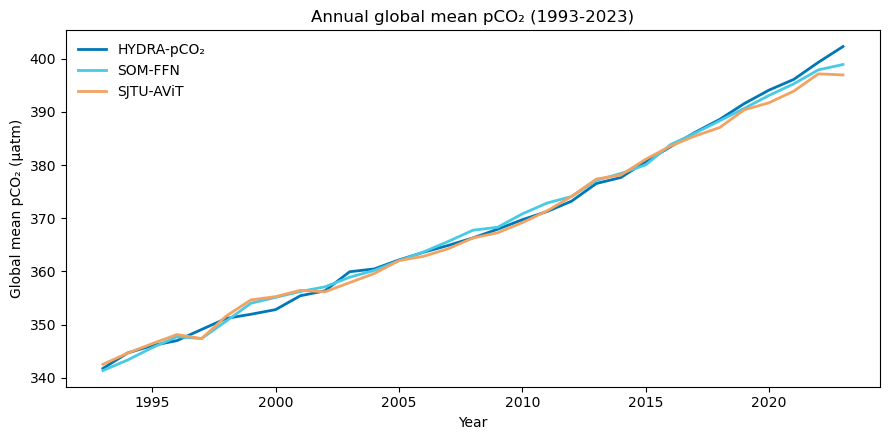

In [8]:
annual_df = pd.DataFrame(
    {
        "Year": pd.DatetimeIndex(
            annual_global_mean(posterior).time.values
        ).year,
        "HYDRA-pCO₂": annual_global_mean(posterior).values,
        "SOM-FFN": annual_global_mean(somffn).values,
        "SJTU-AViT": annual_global_mean(sjtu).values,
    }
)

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    annual_df["Year"],
    annual_df["HYDRA-pCO₂"],
    color=COLORS["HYDRA-pCO₂"],
    linewidth=2,
    label="HYDRA-pCO₂",
)

ax.plot(
    annual_df["Year"],
    annual_df["SOM-FFN"],
    color=COLORS["SOM-FFN"],
    linewidth=2,
    label="SOM-FFN",
)

ax.plot(
    annual_df["Year"],
    annual_df["SJTU-AViT"],
    color=COLORS["SJTU-AViT"],
    linewidth=2,
    label="SJTU-AViT",
)

ax.set_xlabel("Year")
ax.set_ylabel("Global mean pCO₂ (µatm)")
ax.set_title("Annual global mean pCO₂ (1993-2023)")
ax.legend(frameon=False)

plt.tight_layout()
save_figure(fig, "annual_global_mean_pco2_1993_2023.png")
plt.show()

## Climatological seasonal cycle

In [9]:
posterior_monthly = climatological_monthly_cycle(posterior)
somffn_monthly = climatological_monthly_cycle(somffn)
sjtu_monthly = climatological_monthly_cycle(sjtu)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]

monthly_df = pd.DataFrame(
    {
        "Month": month_names,
        "HYDRA-pCO₂": posterior_monthly.values,
        "SOM-FFN": somffn_monthly.values,
        "SJTU-AViT": sjtu_monthly.values,
    }
)

monthly_df

,Month,HYDRA-pCO₂,SOM-FFN,SJTU-AViT
0,Jan,368.401367,368.015974,367.312640
1,Feb,370.943856,369.298567,368.343583
2,Mar,371.583172,369.910750,370.047265
3,Apr,370.443397,368.880421,368.932597
4,May,368.102612,366.560565,366.068571
5,Jun,365.522736,366.565559,365.577159
6,Jul,367.629118,369.034585,368.203480
7,Aug,370.213745,370.661746,371.044908
8,Sep,369.792830,370.179145,370.853604
9,Oct,368.385036,369.129649,368.969715


Saved: /home/efs25/GitHub/irp-efs25/figures/product_comparison/seasonal_cycle_global_mean_pco2_1993_2023.png


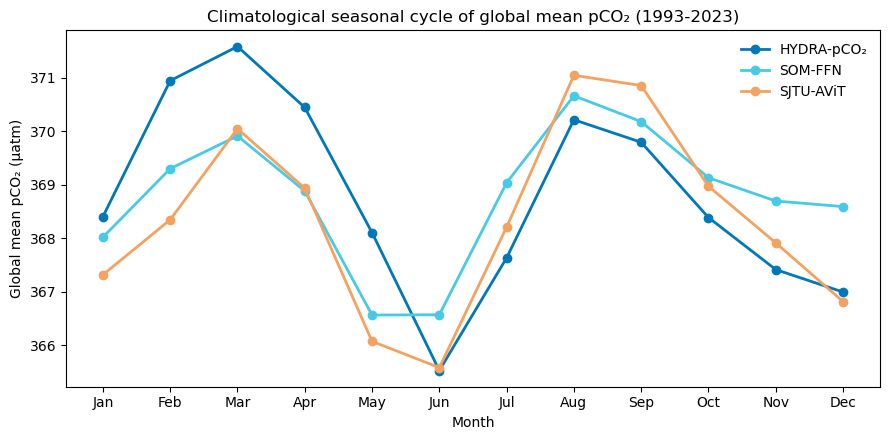

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    monthly_df["Month"],
    monthly_df["HYDRA-pCO₂"],
    color=COLORS["HYDRA-pCO₂"],
    marker="o",
    linewidth=2,
    label="HYDRA-pCO₂",
)

ax.plot(
    monthly_df["Month"],
    monthly_df["SOM-FFN"],
    color=COLORS["SOM-FFN"],
    marker="o",
    linewidth=2,
    label="SOM-FFN",
)

ax.plot(
    monthly_df["Month"],
    monthly_df["SJTU-AViT"],
    color=COLORS["SJTU-AViT"],
    marker="o",
    linewidth=2,
    label="SJTU-AViT",
)

ax.set_xlabel("Month")
ax.set_ylabel("Global mean pCO₂ (µatm)")
ax.set_title("Climatological seasonal cycle of global mean pCO₂ (1993-2023)")
ax.legend(frameon=False)

plt.tight_layout()
save_figure(fig, "seasonal_cycle_global_mean_pco2_1993_2023.png")
plt.show()

## Seasonal means

In [11]:
season_order = ["DJF", "MAM", "JJA", "SON"]

posterior_seasonal = climatological_seasonal_cycle(posterior).sel(
    season=season_order
)
somffn_seasonal = climatological_seasonal_cycle(somffn).sel(
    season=season_order
)
sjtu_seasonal = climatological_seasonal_cycle(sjtu).sel(
    season=season_order
)

seasonal_df = pd.DataFrame(
    {
        "Season": season_order,
        "HYDRA-pCO₂": posterior_seasonal.values,
        "SOM-FFN": somffn_seasonal.values,
        "SJTU-AViT": sjtu_seasonal.values,
    }
)

seasonal_df

,Season,HYDRA-pCO₂,SOM-FFN,SJTU-AViT
0,DJF,368.778637,368.634618,367.497282
1,MAM,370.043060,368.450579,368.349478
2,JJA,367.788533,368.753963,368.275182
3,SON,368.529782,369.334054,369.244655


## Product comparison metrics

In [12]:
metrics = pd.DataFrame(
    {
        "SOM-FFN": comparison_metrics(
            annual_df["SOM-FFN"],
            annual_df["HYDRA-pCO₂"],
        ),
        "SJTU-AViT": comparison_metrics(
            annual_df["SJTU-AViT"],
            annual_df["HYDRA-pCO₂"],
        )
    }
).T

metrics

,MAE,RMSE,Correlation,Bias
SOM-FFN,0.932009,1.169947,0.997909,-0.008300
SJTU-AViT,1.124313,1.566614,0.997320,0.364167


## Seasonal-cycle differences

In [13]:
seasonal_difference_df = pd.DataFrame(
    {
        "Season": season_order,
        "HYDRA-pCO₂ - SOM-FFN": (
            seasonal_df["HYDRA-pCO₂"]
            - seasonal_df["SOM-FFN"]
        ),
        "HYDRA-pCO₂ - SJTU-AViT": (
            seasonal_df["HYDRA-pCO₂"]
            - seasonal_df["SJTU-AViT"]
        )
    }
)


seasonal_difference_df

,Season,HYDRA-pCO₂ - SOM-FFN,HYDRA-pCO₂ - SJTU-AViT
0,DJF,0.144020,1.281355
1,MAM,1.592482,1.693583
2,JJA,-0.965430,-0.486649
3,SON,-0.804272,-0.714873


### Latitudinal breakdown of seasonal cycle

In [ ]:
LAT_BANDS = {
    "Southern (<30°S)": (-90, -30),
    "Tropics/subtropics (30°S–30°N)": (-30, 30),
    "Northern (>30°N)": (30, 90),
}

products = {
    "HYDRA-pCO₂": posterior,
    "SOM-FFN": somffn,
    "SJTU-AViT": sjtu,
}

def area_weighted_band_mean(field, lat_min=None, lat_max=None):
    """
    Area-weighted mean within a latitude band
    """

    band = field

    if lat_min is not None:
        band = band.where(band.lat >= lat_min)

    if lat_max is not None:
        band = band.where(band.lat <= lat_max)

    weights = np.cos(np.deg2rad(band.lat))

    weighted_sum = (
        band * weights
    ).sum(
        dim=("lat", "lon"),
        skipna=True,
    )

    weight_sum = (
        weights.broadcast_like(band)
        .where(np.isfinite(band))
        .sum(
            dim=("lat", "lon"),
            skipna=True,
        )
    )

    return weighted_sum / weight_sum

Calculate seasonal cycles by band

In [ ]:
# calculate seasonal cycles
def seasonal_cycle_by_band(products):
    results = {}

    for band_name, (lat_min, lat_max) in LAT_BANDS.items():

        results[band_name] = {}

        for product_name, field in products.items():

            band_mean = area_weighted_band_mean(
                field,
                lat_min=lat_min,
                lat_max=lat_max,
            )

            seasonal = (
                band_mean
                .groupby("time.month")
                .mean("time")
            )

            results[band_name][product_name] = seasonal

    return results

band_seasonal = seasonal_cycle_by_band(products)

In [18]:
def seasonal_amplitude(seasonal):
    return float(
        seasonal.max() - seasonal.min()
    )


amplitude_rows = []

for band_name, band_data in band_seasonal.items():

    row = {"Latitude band": band_name}

    for product_name, seasonal in band_data.items():
        row[product_name] = seasonal_amplitude(seasonal)

    amplitude_rows.append(row)

amplitude_df = pd.DataFrame(amplitude_rows)

amplitude_df

,Latitude band,HYDRA-pCO₂,SOM-FFN,SJTU-AViT
0,Southern (<30°S),16.218674,9.853618,8.714027
1,Tropics/subtropics (30°S–30°N),7.257569,3.347028,3.394475
2,Northern (>30°N),36.015222,17.197270,20.814061


Saved: /home/efs25/GitHub/irp-efs25/figures/product_comparison/seasonal_cycle_by_latitude_band.png


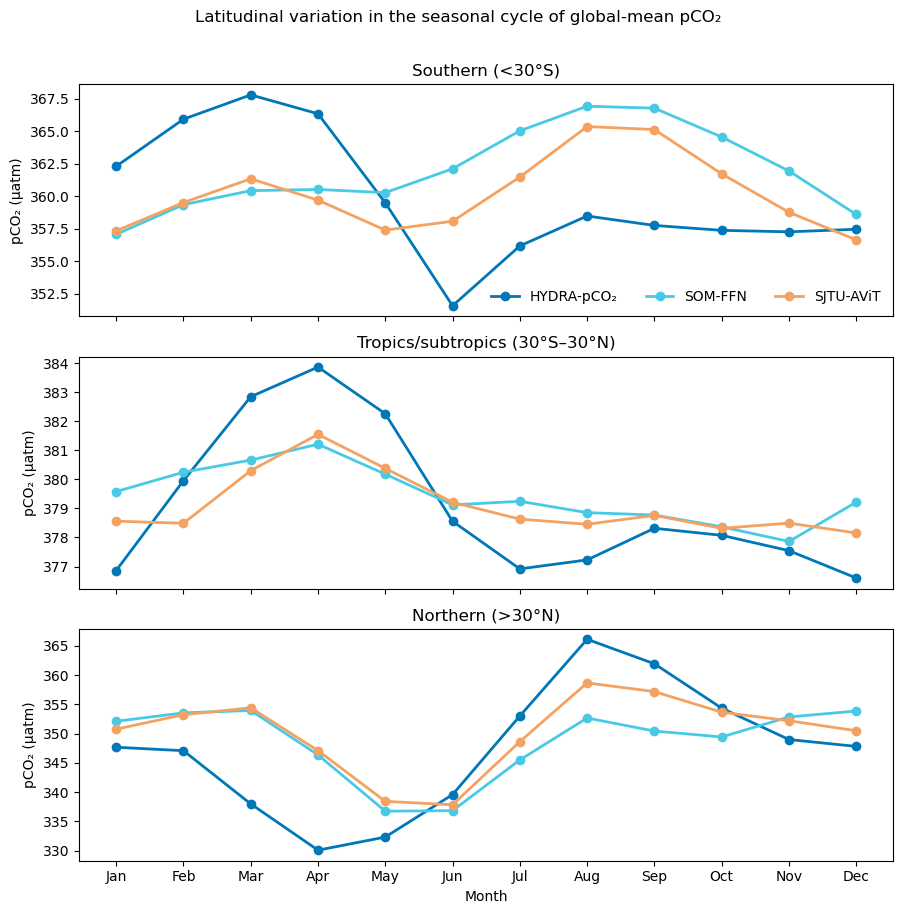

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]

for ax, (band_name, band_data) in zip(axes, band_seasonal.items()):

    for product_name, seasonal in band_data.items():

        ax.plot(
            np.arange(1, 13),
            seasonal.values,
            color=COLORS[product_name],
            marker="o",
            linewidth=2,
            label=product_name,
        )

    ax.set_title(band_name)
    ax.set_ylabel("pCO₂ (µatm)")

axes[-1].set_xticks(np.arange(1, 13))
axes[-1].set_xticklabels(month_names)
axes[-1].set_xlabel("Month")

axes[0].legend(
    frameon=False,
    ncol=3,
)

fig.suptitle("Latitudinal variation in the seasonal cycle of global-mean pCO₂", y=1.01)

plt.tight_layout()

save_figure(fig, "seasonal_cycle_by_latitude_band.png")

plt.show()